In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent   # notebook berada di notebooks/
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)

from src.config import CONFIG
from src.preprocessing import (
    load_data, validate_columns, clean_data, print_cleaning_summary,
)
from src.rfm import calculate_customer_rfm

CONFIG.output_dir.mkdir(parents=True, exist_ok=True)
print("Data path         :", CONFIG.data_path)
print("Sheet             :", CONFIG.sheet_name)
print("Output dir        :", CONFIG.output_dir)
print("Remove non-product:", CONFIG.remove_non_product)

Data path         : D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\data\online_retail_II.xlsx
Sheet             : Year 2010-2011
Output dir        : D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs
Remove non-product: False


In [2]:
raw = load_data(CONFIG.data_path, CONFIG.sheet_name)
print(f"Raw shape: {raw.shape}")   # ekspektasi: (541910, 8)
raw.head()

Raw shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [4]:
df = validate_columns(raw)

print("Dtypes:")
print(df.dtypes, "\n")

print("Missing values per kolom:")
print(df.isna().sum(), "\n")

print("Rentang tanggal:", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
print("Jumlah baris duplikat identik  :", df.duplicated().sum())
print("Invoice cancellation ('C')     :", df["InvoiceNo"].astype(str).str.upper().str.startswith("C").sum())
print("Quantity <= 0                  :", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0                 :", (df["UnitPrice"] <= 0).sum())
print("Tipe InvoiceNo (campuran)      :", df["InvoiceNo"].map(type).value_counts().to_dict())
df[["Quantity", "UnitPrice"]].describe()

Dtypes:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object 

Missing values per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64 

Rentang tanggal: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Jumlah baris duplikat identik  : 5268
Invoice cancellation ('C')     : 9288
Quantity <= 0                  : 10624
UnitPrice <= 0                 : 2517
Tipe InvoiceNo (campuran)      : {<class 'int'>: 532619, <class 'str'>: 9291}


,Quantity,UnitPrice
count,"541,910.00","541,910.00"
mean,9.55,4.61
std,218.08,96.76
min,"-80,995.00","-11,062.06"
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,"80,995.00","38,970.00"


In [5]:
df_clean, cleaning_log = clean_data(df, remove_non_product=CONFIG.remove_non_product)
print_cleaning_summary(cleaning_log)
cleaning_log

PREPROCESSING SUMMARY
Rows before      : 541,910
Rows after       : 392,693
Customers before : 4,372
Customers after  : 4,338
------------------------------------------------------------
remove_invalid_invoice_date         removed:          0
remove_missing_customer_id          removed:    135,080
remove_duplicate_rows               removed:      5,225
remove_cancellation                 removed:      8,872
remove_non_positive_quantity        removed:          0
remove_non_positive_unit_price      removed:         40


,step,rows_before,rows_after,rows_removed,customers_after
0,initial,541910,541910,0,4372
1,remove_invalid_invoice_date,541910,541910,0,4372
2,remove_missing_customer_id,541910,406830,135080,4372
3,remove_duplicate_rows,406830,401605,5225,4372
4,remove_cancellation,401605,392733,8872,4339
5,remove_non_positive_quantity,392733,392733,0,4339
6,remove_non_positive_unit_price,392733,392693,40,4338


In [6]:
# Validasi log: baris awal - total dihapus = baris akhir
initial_rows = int(cleaning_log.iloc[0]["rows_before"])
total_removed = int(cleaning_log["rows_removed"].sum())
assert initial_rows - total_removed == len(df_clean), "Log preprocessing tidak konsisten"
print(f"OK: {initial_rows:,} - {total_removed:,} = {len(df_clean):,}")

OK: 541,910 - 149,217 = 392,693


In [7]:
non_product = df_clean[~df_clean["StockCode"].str.match(r"^\d{5}")]
print(f"Baris StockCode non-produk pada data bersih: {len(non_product):,}")
print(f"Revenue dari baris tersebut               : {non_product['Revenue'].sum():,.2f}")
non_product["StockCode"].value_counts()

Baris StockCode non-produk pada data bersih: 1,543
Revenue dari baris tersebut               : 149,999.25


StockCode
POST            1100
M                279
C2               133
DOT               16
BANK CHARGES      12
PADS               3
Name: count, dtype: int64

In [8]:
df_clean.to_csv(CONFIG.output_dir / "cleaned_data.csv", index=False)
cleaning_log.to_csv(CONFIG.output_dir / "cleaning_log.csv", index=False)
print("Tersimpan: cleaned_data.csv, cleaning_log.csv")
df_clean.head()

Tersimpan: cleaned_data.csv, cleaning_log.csv


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [9]:
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Reference date:", reference_date)

rfm = calculate_customer_rfm(df_clean, reference_date=reference_date)
print(f"Jumlah customer: {len(rfm):,}")
rfm.head(10)

Reference date: 2011-12-10 12:50:00
Jumlah customer: 4,338


,CustomerID,LastPurchaseDate,Recency,Frequency,Monetary
0,12346,2011-01-18 10:01:00,326,1,"77,183.60"
1,12347,2011-12-07 15:52:00,2,7,"4,310.00"
2,12348,2011-09-25 13:13:00,75,4,"1,797.24"
3,12349,2011-11-21 09:51:00,19,1,"1,757.55"
4,12350,2011-02-02 16:01:00,310,1,334.40
5,12352,2011-11-03 14:37:00,36,8,"2,506.04"
6,12353,2011-05-19 17:47:00,204,1,89.00
7,12354,2011-04-21 13:11:00,232,1,"1,079.40"
8,12355,2011-05-09 13:49:00,214,1,459.40
9,12356,2011-11-17 08:40:00,23,3,"2,811.43"


In [10]:
assert rfm["CustomerID"].is_unique, "CustomerID tidak unik"
assert len(rfm) == df_clean["CustomerID"].nunique(), "Jumlah customer tidak konsisten"
assert (rfm["Recency"] >= 1).all(), "Recency < 1 ditemukan"
assert (rfm["Frequency"] >= 1).all(), "Frequency < 1 ditemukan"
assert (rfm["Monetary"] > 0).all(), "Monetary <= 0 ditemukan"
assert np.isclose(rfm["Monetary"].sum(), df_clean["Revenue"].sum()), "Total Monetary != total Revenue"
print("Semua sanity check lolos.\n")

# Verifikasi manual satu customer
cid = rfm["CustomerID"].iloc[0]
sub = df_clean[df_clean["CustomerID"] == cid]
print(f"Customer {cid}:")
print("  Last purchase manual :", sub["InvoiceDate"].max())
print("  Recency manual       :", (reference_date - sub["InvoiceDate"].max()).days)
print("  Frequency manual     :", sub["InvoiceNo"].nunique())
print("  Monetary manual      :", round(sub["Revenue"].sum(), 2))
print("Bandingkan dengan baris pertama tabel RFM di atas.")

Semua sanity check lolos.

Customer 12346:
  Last purchase manual : 2011-01-18 10:01:00
  Recency manual       : 326
  Frequency manual     : 1
  Monetary manual      : 77183.6
Bandingkan dengan baris pertama tabel RFM di atas.


In [11]:
print(rfm[["Recency", "Frequency", "Monetary"]].describe())
print(f"\nCustomer dengan Frequency = 1 : {(rfm['Frequency'] == 1).mean():.1%}")
print("Monetary tertinggi:")
print(rfm.nlargest(5, "Monetary")[["CustomerID", "Frequency", "Monetary"]])
print("\nSkewness (nilai besar = sangat miring ke kanan):")
print(rfm[["Recency", "Frequency", "Monetary"]].skew())

       Recency  Frequency   Monetary
count 4,338.00   4,338.00   4,338.00
mean     92.54       4.27   2,048.69
std     100.01       7.70   8,985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00   1,660.60
max     374.00     209.00 280,206.02

Customer dengan Frequency = 1 : 34.4%
Monetary tertinggi:
      CustomerID  Frequency   Monetary
1689       14646         73 280,206.02
4201       18102         60 259,657.30
3728       17450         46 194,390.79
3008       16446          2 168,472.50
1879       14911        201 143,711.17

Skewness (nilai besar = sangat miring ke kanan):
Recency      1.25
Frequency   12.07
Monetary    19.34
dtype: float64


In [12]:
rfm.to_csv(CONFIG.output_dir / "customer_rfm.csv", index=False)
print("Tersimpan:", CONFIG.output_dir / "customer_rfm.csv")

Tersimpan: D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs\customer_rfm.csv


In [13]:
from src.clv import (
    create_calibration_holdout, build_clv_summary, fit_bgnbd, diagnose_bgnbd,
    fit_gamma_gamma, calculate_predictive_clv, evaluate_clv_prediction,
)
import matplotlib.pyplot as plt

In [14]:
calibration, holdout, cutoff = create_calibration_holdout(df_clean, CONFIG.holdout_days)

print("Cutoff calibration :", cutoff.date())
print(f"Calibration : {calibration['InvoiceDate'].min()} -> {calibration['InvoiceDate'].max()}  ({len(calibration):,} baris, {calibration['CustomerID'].nunique():,} customer)")
print(f"Holdout     : {holdout['InvoiceDate'].min()} -> {holdout['InvoiceDate'].max()}  ({len(holdout):,} baris, {holdout['CustomerID'].nunique():,} customer)")

new_in_holdout = set(holdout["CustomerID"]) - set(calibration["CustomerID"])
print(f"Customer yang baru muncul di holdout (tidak bisa diprediksi): {len(new_in_holdout):,}")

# Cek anti-leakage
assert calibration["InvoiceDate"].max() < holdout["InvoiceDate"].min(), "Calibration dan holdout tumpang tindih"
assert len(calibration) + len(holdout) == len(df_clean), "Ada baris hilang saat split"
print("Cek split: OK")

Cutoff calibration : 2011-09-10
Calibration : 2010-12-01 08:26:00 -> 2011-09-09 15:53:00  (233,840 baris, 3,370 customer)
Holdout     : 2011-09-11 10:35:00 -> 2011-12-09 12:50:00  (158,853 baris, 2,889 customer)
Customer yang baru muncul di holdout (tidak bisa diprediksi): 968
Cek split: OK


In [15]:
summary_cal = build_clv_summary(calibration, cutoff)
print(f"Customer di calibration: {len(summary_cal):,}")
print(f"Tanpa pembelian ulangan (lt_frequency = 0): {(summary_cal['lt_frequency'] == 0).mean():.1%}")
display(summary_cal.describe())

bgf, used_pen = fit_bgnbd(summary_cal, CONFIG.bgnbd_penalizer)
diag = diagnose_bgnbd(bgf)
print("\nBG/NBD  penalizer dipakai:", used_pen)
print("BG/NBD  parameter        :", diag["params"])
print("BG/NBD  dropout degenerate:", diag["dropout_degenerate"])

ggf, corr_fm = fit_gamma_gamma(summary_cal, CONFIG.gg_penalizer)
print("\nGamma-Gamma parameter    :", {k: round(float(v), 3) for k, v in ggf.params_.items()})
print(f"Korelasi frequency-monetary (asumsi independen; idealnya kecil): {corr_fm:.3f}")

Customer di calibration: 3,370
Tanpa pembelian ulangan (lt_frequency = 0): 42.0%


,lt_frequency,lt_recency,lt_T,lt_monetary
count,"3,370.00","3,370.00","3,370.00","3,370.00"
mean,2.21,87.91,182.90,242.22
std,4.63,95.48,80.46,566.47
min,0.00,0.00,1.00,0.00
25%,0.00,0.00,123.00,0.00
50%,1.00,55.00,193.00,135.01
75%,3.00,170.00,265.00,328.47
max,82.00,282.00,283.00,"21,535.90"



BG/NBD  penalizer dipakai: 0.05
BG/NBD  parameter        : {'r': 0.5938, 'alpha': 54.008, 'a': 0.0, 'b': 0.0}
BG/NBD  dropout degenerate: True

Gamma-Gamma parameter    : {'p': 2.332, 'q': 3.334, 'v': 410.207}
Korelasi frequency-monetary (asumsi independen; idealnya kecil): 0.105


In [16]:
eval_months = int(round(CONFIG.holdout_days / 30))   # horizon prediksi = panjang holdout
pred_cal = calculate_predictive_clv(bgf, ggf, summary_cal, eval_months, CONFIG.discount_rate)

metrics, decile = evaluate_clv_prediction(summary_cal, pred_cal, holdout)
print(f"Horizon evaluasi: {eval_months} bulan (= {CONFIG.holdout_days} hari holdout)\n")
pd.Series(metrics).to_frame("value")

Horizon evaluasi: 3 bulan (= 90 hari holdout)



,value
n_customers_evaluated,"3,370.00"
n_active_in_holdout,"1,921.00"
purchases_spearman,0.50
purchases_pearson,0.79
purchases_MAE,0.93
purchases_RMSE,1.51
purchases_total_predicted,"3,314.24"
purchases_total_actual,"4,482.00"
clv_spearman_vs_revenue,0.51
clv_pearson_vs_revenue,0.66


In [17]:
decile

,CLV_Decile,n,mean_predicted_clv,mean_actual_revenue,mean_expected_purchases,mean_actual_purchases
0,1,337,70.08,164.16,0.17,0.49
1,2,337,91.80,209.40,0.23,0.46
2,3,337,119.30,708.31,0.34,0.54
3,4,337,153.36,286.37,0.48,0.80
4,5,337,197.06,244.20,0.65,0.86
5,6,337,244.35,305.46,0.79,0.99
6,7,337,309.03,410.28,0.95,1.12
7,8,337,406.30,602.88,1.27,1.48
8,9,337,610.52,"1,074.72",1.67,2.19
9,10,337,"2,372.01","4,432.96",3.27,4.37


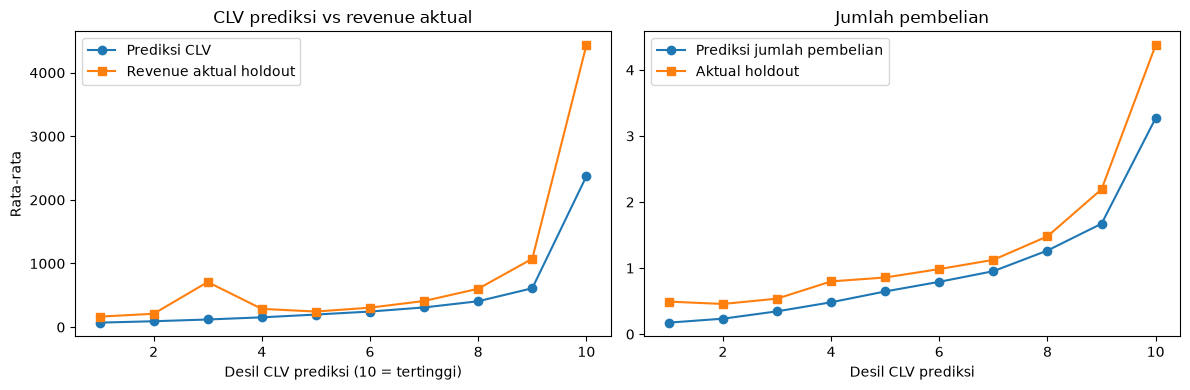

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(decile["CLV_Decile"], decile["mean_predicted_clv"], marker="o", label="Prediksi CLV")
ax[0].plot(decile["CLV_Decile"], decile["mean_actual_revenue"], marker="s", label="Revenue aktual holdout")
ax[0].set_xlabel("Desil CLV prediksi (10 = tertinggi)"); ax[0].set_ylabel("Rata-rata"); ax[0].set_title("CLV prediksi vs revenue aktual"); ax[0].legend()
ax[1].plot(decile["CLV_Decile"], decile["mean_expected_purchases"], marker="o", label="Prediksi jumlah pembelian")
ax[1].plot(decile["CLV_Decile"], decile["mean_actual_purchases"], marker="s", label="Aktual holdout")
ax[1].set_xlabel("Desil CLV prediksi"); ax[1].set_title("Jumlah pembelian"); ax[1].legend()
plt.tight_layout(); plt.show()

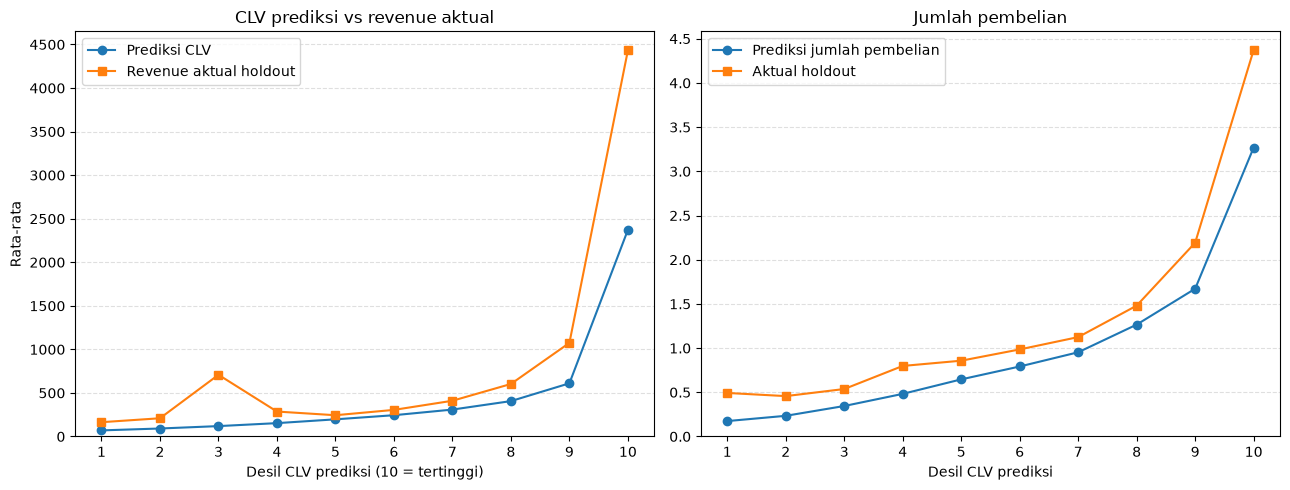

In [45]:
from matplotlib.ticker import MultipleLocator

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Grafik kiri: CLV prediksi vs revenue aktual
ax[0].plot(decile["CLV_Decile"], decile["mean_predicted_clv"], marker="o", label="Prediksi CLV")
ax[0].plot(decile["CLV_Decile"], decile["mean_actual_revenue"], marker="s", label="Revenue aktual holdout")
ax[0].set_xlabel("Desil CLV prediksi (10 = tertinggi)")
ax[0].set_ylabel("Rata-rata")
ax[0].set_title("CLV prediksi vs revenue aktual")
ax[0].yaxis.set_major_locator(MultipleLocator(500))   # jarak sumbu-Y = 500
ax[0].set_ylim(bottom=0)
ax[0].xaxis.set_major_locator(MultipleLocator(1))     # semua desil 1-10 tampil
ax[0].grid(axis="y", linestyle="--", alpha=0.4)
ax[0].legend()

# Grafik kanan: jumlah pembelian
ax[1].plot(decile["CLV_Decile"], decile["mean_expected_purchases"], marker="o", label="Prediksi jumlah pembelian")
ax[1].plot(decile["CLV_Decile"], decile["mean_actual_purchases"], marker="s", label="Aktual holdout")
ax[1].set_xlabel("Desil CLV prediksi")
ax[1].set_title("Jumlah pembelian")
ax[1].yaxis.set_major_locator(MultipleLocator(0.5))   # jarak sumbu-Y = 0,5
ax[1].set_ylim(bottom=0)
ax[1].xaxis.set_major_locator(MultipleLocator(1))
ax[1].grid(axis="y", linestyle="--", alpha=0.4)
ax[1].legend()

plt.tight_layout()
plt.show()

In [19]:
print("Ringkasan evaluasi CLV")
print(f"  Spearman CLV vs revenue aktual      : {metrics['clv_spearman_vs_revenue']:.3f}")
print(f"  Pembanding naif (Frequency)         : {metrics['baseline_spearman_frequency']:.3f}")
print(f"  Pembanding naif (Monetary historis) : {metrics['baseline_spearman_hist_monetary']:.3f}")
print(f"  Total pembelian prediksi vs aktual  : {metrics['purchases_total_predicted']:,.0f} vs {metrics['purchases_total_actual']:,.0f}")
print(f"  Total CLV prediksi vs revenue aktual: {metrics['clv_total_predicted']:,.0f} vs {metrics['revenue_total_actual']:,.0f}")
pd.Series(metrics).to_frame("value").to_csv(CONFIG.output_dir / "clv_evaluation_metrics.csv")
decile.to_csv(CONFIG.output_dir / "clv_decile_table.csv", index=False)

Ringkasan evaluasi CLV
  Spearman CLV vs revenue aktual      : 0.513
  Pembanding naif (Frequency)         : 0.493
  Pembanding naif (Monetary historis) : 0.525
  Total pembelian prediksi vs aktual  : 3,314 vs 4,482
  Total CLV prediksi vs revenue aktual: 1,541,367 vs 2,843,857


In [20]:
from src.clv import evaluate_clv_multi_split, compare_counting_models

multi_split = evaluate_clv_multi_split(
    df_clean,
    holdout_days_list=(30, 60, 90, 120, 150),
    bgnbd_penalizer=CONFIG.bgnbd_penalizer,
    gg_penalizer=CONFIG.gg_penalizer,
    clv_horizon_months=CONFIG.clv_horizon_months,
    discount_rate=CONFIG.discount_rate,
)
multi_split.to_csv(CONFIG.output_dir / "clv_multi_split_evaluation.csv", index=False)
multi_split

,holdout_days,cutoff,n_customers,dropout_degenerate,purchases_total_predicted,purchases_total_actual,purchases_ratio,purchases_spearman,clv_spearman_vs_revenue,baseline_spearman_hist_monetary
0,30,2011-11-09,4086,True,"1,371.38","2,123.00",0.65,0.42,0.42,0.42
1,60,2011-10-10,3741,True,"2,468.04","3,486.00",0.71,0.46,0.47,0.49
2,90,2011-09-10,3370,True,"3,314.24","4,482.00",0.74,0.50,0.51,0.52
3,120,2011-08-11,3218,True,"4,357.65","5,329.00",0.82,0.52,0.54,0.56
4,150,2011-07-12,3027,True,"5,330.91","6,151.00",0.87,0.52,0.53,0.56


In [21]:
print("=== Ringkasan stabilitas lintas 5 split ===")
print(f"Rasio prediksi/aktual : rata-rata {multi_split['purchases_ratio'].mean():.3f}  (std {multi_split['purchases_ratio'].std():.3f})")
print(f"Spearman CLV          : rata-rata {multi_split['clv_spearman_vs_revenue'].mean():.3f}  (std {multi_split['clv_spearman_vs_revenue'].std():.3f})")
print(f"Spearman baseline(M)  : rata-rata {multi_split['baseline_spearman_hist_monetary'].mean():.3f}")
print(f"\nDropout terdegenerasi pada seluruh split: {multi_split['dropout_degenerate'].all()}")
print(f"CLV mengalahkan baseline Monetary historis pada berapa dari {len(multi_split)} split: "
      f"{(multi_split['clv_spearman_vs_revenue'] > multi_split['baseline_spearman_hist_monetary']).sum()}")
print("\nRasio membaik (mendekati 1.0) seiring holdout makin panjang -> mendukung dugaan")
print("bahwa under-prediction pada holdout 90 hari terkait proporsi periode musiman di dalamnya,")
print("bukan semata kelemahan model.")

=== Ringkasan stabilitas lintas 5 split ===
Rasio prediksi/aktual : rata-rata 0.756  (std 0.088)
Spearman CLV          : rata-rata 0.493  (std 0.050)
Spearman baseline(M)  : rata-rata 0.509

Dropout terdegenerasi pada seluruh split: True
CLV mengalahkan baseline Monetary historis pada berapa dari 5 split: 0

Rasio membaik (mendekati 1.0) seiring holdout makin panjang -> mendukung dugaan
bahwa under-prediction pada holdout 90 hari terkait proporsi periode musiman di dalamnya,
bukan semata kelemahan model.


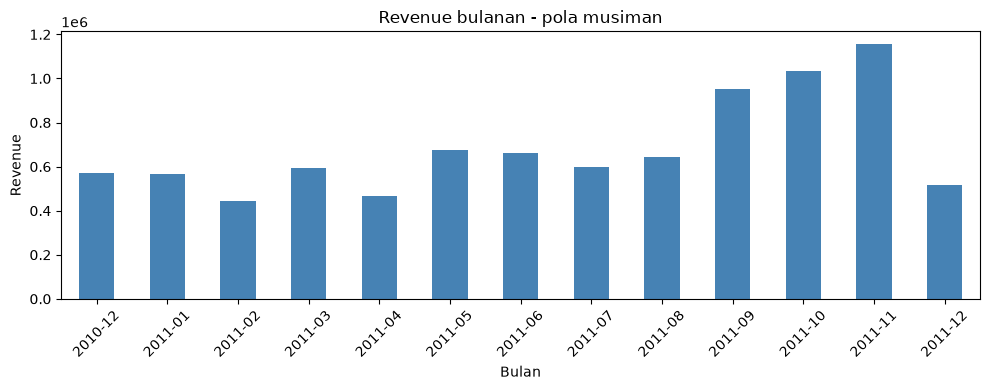

Rata-rata revenue Sep-Nov 2011 : 1,047,513
Rata-rata revenue bulan lain   : 574,469
Rasio                          : 1.82x

Holdout 90 hari (cutoff 10 Sep) mencakup hampir seluruh periode lonjakan ini,
sedangkan calibration (Des 2010 - Sep 2011) sebagian besar periode yang relatif datar.


In [22]:
monthly = df_clean.copy()
monthly["Month"] = monthly["InvoiceDate"].dt.to_period("M")
monthly_revenue = monthly.groupby("Month")["Revenue"].sum()

fig, ax = plt.subplots(figsize=(10, 4))
monthly_revenue.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Revenue bulanan - pola musiman")
ax.set_xlabel("Bulan"); ax.set_ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

peak_months = ["2011-09", "2011-10", "2011-11"]
peak_avg = monthly_revenue.loc[peak_months].mean()
other_avg = monthly_revenue.drop(peak_months).mean()
print(f"Rata-rata revenue Sep-Nov 2011 : {peak_avg:,.0f}")
print(f"Rata-rata revenue bulan lain   : {other_avg:,.0f}")
print(f"Rasio                          : {peak_avg/other_avg:.2f}x")
print("\nHoldout 90 hari (cutoff 10 Sep) mencakup hampir seluruh periode lonjakan ini,")
print("sedangkan calibration (Des 2010 - Sep 2011) sebagian besar periode yang relatif datar.")

In [23]:
model_comparison = compare_counting_models(summary_cal, CONFIG.bgnbd_penalizer)
for _, r in model_comparison.iterrows():
    print(f"{r['Model']:18s} params={r['Params']}  mean P(alive)={r['MeanProbAlive']:.6f}  std={r['StdProbAlive']:.2e}")

print("\nKesimpulan: ketiga model konvergen ke P(alive) ~ 1.0 untuk semua customer")
print("(parameter dropout a, b, atau s mendekati 0). Ini mengonfirmasi dropout terdegenerasi")
print("adalah karakteristik data (diduga: 42% customer calibration hanya membeli sekali),")
print("bukan kelemahan satu model tertentu. Mengganti BG/NBD dengan Pareto/NBD atau")
print("Modified BG/NBD TIDAK mengubah kesimpulan ini.")

non_repeat_pct = (summary_cal["lt_frequency"] == 0).mean()
print(f"\nProporsi customer calibration dengan hanya 1x pembelian (non-repeater): {non_repeat_pct:.1%}")

BG/NBD             params={'r': 0.5938, 'alpha': 54.008, 'a': 0.0, 'b': 0.0}  mean P(alive)=1.000000  std=8.92e-10
Pareto/NBD         params={'r': 0.7235, 'alpha': 66.1547, 's': 0.0, 'beta': 19.7223}  mean P(alive)=1.000000  std=3.49e-12
Modified BG/NBD    params={'r': 0.5938, 'alpha': 54.008, 'a': 0.0, 'b': 0.0}  mean P(alive)=1.000000  std=6.46e-10

Kesimpulan: ketiga model konvergen ke P(alive) ~ 1.0 untuk semua customer
(parameter dropout a, b, atau s mendekati 0). Ini mengonfirmasi dropout terdegenerasi
adalah karakteristik data (diduga: 42% customer calibration hanya membeli sekali),
bukan kelemahan satu model tertentu. Mengganti BG/NBD dengan Pareto/NBD atau
Modified BG/NBD TIDAK mengubah kesimpulan ini.

Proporsi customer calibration dengan hanya 1x pembelian (non-repeater): 42.0%


In [24]:
obs_end = df_clean["InvoiceDate"].max().normalize()
summary_full = build_clv_summary(df_clean, obs_end)
assert len(summary_full) == df_clean["CustomerID"].nunique()

bgf_full, pen_full = fit_bgnbd(summary_full, CONFIG.bgnbd_penalizer)
ggf_full, corr_full = fit_gamma_gamma(summary_full, CONFIG.gg_penalizer)
print("BG/NBD :", diagnose_bgnbd(bgf_full), "| penalizer:", pen_full)
print("Gamma-Gamma:", {k: round(float(v), 3) for k, v in ggf_full.params_.items()}, "| corr F-M:", round(corr_full, 3))

clv_full = calculate_predictive_clv(bgf_full, ggf_full, summary_full, CONFIG.clv_horizon_months, CONFIG.discount_rate)

# Cek kewajaran
assert clv_full["PredictiveCLV"].notna().all(), "Ada CLV NaN"
assert (clv_full["PredictiveCLV"] >= 0).all(), "Ada CLV negatif"
print(f"\nCustomer dengan prediksi diimputasi (ekspektasi populasi): {int(clv_full['ImputedPrediction'].sum())}")
clv_full.describe(percentiles=[0.5, 0.9, 0.99])

BG/NBD : {'params': {'r': 0.6696, 'alpha': 55.8394, 'a': 0.0, 'b': 0.0}, 'dropout_degenerate': True} | penalizer: 0.05
Gamma-Gamma: {'p': 2.111, 'q': 3.437, 'v': 479.646} | corr F-M: 0.016

Customer dengan prediksi diimputasi (ekspektasi populasi): 26


,ProbAlive,ExpectedPurchases,ExpectedAOV,PredictiveCLV
count,"4,338.00","4,338.00","4,338.00","4,338.00"
mean,1.00,1.08,439.69,520.86
std,0.00,1.32,"1,235.43","1,904.29"
min,1.00,0.14,46.89,57.23
50%,1.00,0.74,415.37,258.72
90%,1.00,2.22,532.14,865.64
99%,1.00,5.67,"1,466.35","3,853.99"
max,1.00,27.63,"78,408.37","59,761.30"


In [25]:
clv_full.reset_index().to_csv(CONFIG.output_dir / "clv_predictions.csv", index=False)
print("Tersimpan: clv_predictions.csv")

Tersimpan: clv_predictions.csv


In [26]:
features = rfm.merge(
    clv_full[["ExpectedPurchases", "ExpectedAOV", "PredictiveCLV", "ImputedPrediction"]].reset_index(),
    on="CustomerID", how="left", validate="one_to_one",
)
assert features["PredictiveCLV"].notna().all() and len(features) == len(rfm)
assert features["CustomerID"].is_unique

FEATURE_COLS = ["Recency", "Frequency", "Monetary", "PredictiveCLV"]
features.to_csv(CONFIG.output_dir / "customer_features.csv", index=False)
print(f"Customer: {len(features):,} | fitur clustering: {FEATURE_COLS}")
features[["CustomerID"] + FEATURE_COLS].head(10)

Customer: 4,338 | fitur clustering: ['Recency', 'Frequency', 'Monetary', 'PredictiveCLV']


,CustomerID,Recency,Frequency,Monetary,PredictiveCLV
0,12346,326,1,"77,183.60",64.44
1,12347,2,7,"4,310.00",793.19
2,12348,75,4,"1,797.24",260.63
3,12349,19,1,"1,757.55",332.36
4,12350,310,1,334.40,67.08
5,12352,36,8,"2,506.04",628.64
6,12353,204,1,89.00,94.45
7,12354,232,1,"1,079.40",85.26
8,12355,214,1,459.40,90.95
9,12356,23,3,"2,811.43",199.86


In [27]:
print("Korelasi Spearman antar fitur:")
display(features[FEATURE_COLS].corr(method="spearman").round(3))
print("Korelasi Pearson antar fitur:")
display(features[FEATURE_COLS].corr(method="pearson").round(3))
print("Skewness:"); print(features[FEATURE_COLS].skew().round(2))

Korelasi Spearman antar fitur:


,Recency,Frequency,Monetary,PredictiveCLV
Recency,1.00,-0.56,-0.48,-0.77
Frequency,-0.56,1.00,0.81,0.73
Monetary,-0.48,0.81,1.00,0.74
PredictiveCLV,-0.77,0.73,0.74,1.00


Korelasi Pearson antar fitur:


,Recency,Frequency,Monetary,PredictiveCLV
Recency,1.00,-0.26,-0.12,-0.16
Frequency,-0.26,1.00,0.55,0.53
Monetary,-0.12,0.55,1.00,0.96
PredictiveCLV,-0.16,0.53,0.96,1.00


Skewness:
Recency          1.25
Frequency       12.07
Monetary        19.34
PredictiveCLV   19.44
dtype: float64


In [28]:
import joblib
from src.clustering import standardize_features

X_scaled, scaler, X_pre = standardize_features(
    features, FEATURE_COLS,
    log_transform=CONFIG.log_transform, log_features=CONFIG.log_features,
)
print("log_transform:", CONFIG.log_transform, "| log_features:", CONFIG.log_features)
print("\nSkewness sebelum -> sesudah transformasi + scaling:")
print(pd.DataFrame({"before": features[FEATURE_COLS].skew(), "after": X_scaled.skew()}).round(2))

# Cek: mean ~ 0 dan std ~ 1
assert np.allclose(X_scaled.mean(), 0, atol=1e-8), "Mean tidak ~ 0"
assert np.allclose(X_scaled.std(ddof=0), 1, atol=1e-8), "Std tidak ~ 1"
print("\nCek standardisasi: OK (mean ~ 0, std ~ 1)")
X_scaled.describe().round(3)

log_transform: True | log_features: ('Frequency', 'Monetary', 'PredictiveCLV')

Skewness sebelum -> sesudah transformasi + scaling:
               before  after
Recency          1.25   1.25
Frequency       12.07   1.21
Monetary        19.34   0.40
PredictiveCLV   19.44   0.83

Cek standardisasi: OK (mean ~ 0, std ~ 1)


,Recency,Frequency,Monetary,PredictiveCLV
count,"4,338.00","4,338.00","4,338.00","4,338.00"
mean,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-0.92,-0.95,-4.00,-1.67
25%,-0.74,-0.95,-0.68,-0.68
50%,-0.41,-0.36,-0.07,-0.06
75%,0.49,0.65,0.66,0.56
max,2.81,5.86,4.73,5.82


In [29]:
joblib.dump(scaler, CONFIG.output_dir / "scaler.joblib")
X_out = X_scaled.copy(); X_out.insert(0, "CustomerID", features["CustomerID"].values)
X_out.to_csv(CONFIG.output_dir / "customer_features_scaled.csv", index=False)
print("Tersimpan: scaler.joblib, customer_features_scaled.csv")

Tersimpan: scaler.joblib, customer_features_scaled.csv


In [30]:
from src.clustering import run_kmeans_for_multiple_k

print(f"Kandidat K: {list(CONFIG.candidate_k)}")
print(f"n_init={CONFIG.n_init}, random_state={CONFIG.random_state}, max_iter={CONFIG.max_iter}\n")

kmeans_results = run_kmeans_for_multiple_k(
    X_scaled, CONFIG.candidate_k,
    random_state=CONFIG.random_state, n_init=CONFIG.n_init, max_iter=CONFIG.max_iter,
)

Kandidat K: [2, 3, 4, 5, 6, 7, 8, 9, 10]
n_init=20, random_state=42, max_iter=300

  K=2  selesai | inertia=9,027.9
  K=3  selesai | inertia=5,705.7
  K=4  selesai | inertia=4,359.9
  K=5  selesai | inertia=3,750.9
  K=6  selesai | inertia=3,292.6
  K=7  selesai | inertia=2,983.0
  K=8  selesai | inertia=2,741.4
  K=9  selesai | inertia=2,522.8
  K=10 selesai | inertia=2,372.9


In [31]:
from src.evaluation import calculate_clustering_metrics

metrics_df = calculate_clustering_metrics(X_scaled, kmeans_results)
metrics_df.to_csv(CONFIG.output_dir / "clustering_evaluation_raw.csv", index=False)
metrics_df

,K,Silhouette,DBI,CHI
0,2,0.41,0.90,"3,998.01"
1,3,0.41,0.83,"4,424.27"
2,4,0.37,0.89,"4,304.97"
3,5,0.33,0.98,"3,927.97"
4,6,0.32,1.01,"3,699.56"
5,7,0.29,1.06,"3,477.07"
6,8,0.29,1.04,"3,296.76"
7,9,0.27,1.08,"3,180.80"
8,10,0.28,1.11,"3,035.60"


In [32]:
print("Cara membaca: Silhouette (tinggi=baik), DBI (rendah=baik), CHI (tinggi=baik).\n")
print("K dengan Silhouette terbaik :", int(metrics_df.loc[metrics_df['Silhouette'].idxmax(), 'K']))
print("K dengan DBI terbaik        :", int(metrics_df.loc[metrics_df['DBI'].idxmin(), 'K']))
print("K dengan CHI terbaik        :", int(metrics_df.loc[metrics_df['CHI'].idxmax(), 'K']))
print("\nJika ketiganya berbeda, itu wajar (lihat Step 9: Adaptive K Selection).")

Cara membaca: Silhouette (tinggi=baik), DBI (rendah=baik), CHI (tinggi=baik).

K dengan Silhouette terbaik : 2
K dengan DBI terbaik        : 3
K dengan CHI terbaik        : 3

Jika ketiganya berbeda, itu wajar (lihat Step 9: Adaptive K Selection).


In [33]:
from src.evaluation import rank_k_candidates, select_optimal_k

ranked_df = rank_k_candidates(metrics_df)  # weights default: Silhouette=DBI=CHI=1
selected_k, ranked_df = select_optimal_k(ranked_df)

print(f"\nK terpilih berdasarkan multi-metric ranking: {selected_k}")
print("(Catatan: ini adalah K yang paling sesuai berdasarkan kriteria evaluasi yang dipakai,")
print(" bukan K yang 'benar' secara absolut. Kandidat K lain tetap tersedia di tabel di bawah.)")
ranked_df.to_csv(CONFIG.output_dir / "clustering_evaluation.csv", index=False)
ranked_df


K terpilih berdasarkan multi-metric ranking: 3
(Catatan: ini adalah K yang paling sesuai berdasarkan kriteria evaluasi yang dipakai,
 bukan K yang 'benar' secara absolut. Kandidat K lain tetap tersedia di tabel di bawah.)


,K,Silhouette,DBI,CHI,Rank_Silhouette,Rank_DBI,Rank_CHI,TotalRank
0,3,0.41,0.83,"4,424.27",2.00,1.00,1.00,4.00
1,2,0.41,0.90,"3,998.01",1.00,3.00,3.00,7.00
2,4,0.37,0.89,"4,304.97",3.00,2.00,2.00,7.00
3,5,0.33,0.98,"3,927.97",4.00,4.00,4.00,12.00
4,6,0.32,1.01,"3,699.56",5.00,5.00,5.00,15.00
5,7,0.29,1.06,"3,477.07",6.00,7.00,6.00,19.00
6,8,0.29,1.04,"3,296.76",7.00,6.00,7.00,20.00
7,9,0.27,1.08,"3,180.80",9.00,8.00,8.00,25.00
8,10,0.28,1.11,"3,035.60",8.00,9.00,9.00,26.00


In [34]:
print("Perbandingan K terbaik per metric vs hasil ranking gabungan:")
print(f"  Silhouette saja : K={int(metrics_df.loc[metrics_df['Silhouette'].idxmax(), 'K'])}")
print(f"  DBI saja        : K={int(metrics_df.loc[metrics_df['DBI'].idxmin(), 'K'])}")
print(f"  CHI saja        : K={int(metrics_df.loc[metrics_df['CHI'].idxmax(), 'K'])}")
print(f"  Multi-metric rank: K={selected_k}")

Perbandingan K terbaik per metric vs hasil ranking gabungan:
  Silhouette saja : K=2
  DBI saja        : K=3
  CHI saja        : K=3
  Multi-metric rank: K=3


In [35]:
from src.clustering import run_kmeans

final_model = run_kmeans(
    X_scaled, selected_k,
    random_state=CONFIG.random_state, n_init=CONFIG.n_init, max_iter=CONFIG.max_iter,
)

customer_segments = features.copy()
customer_segments["Cluster"] = final_model.labels_

assert customer_segments["Cluster"].nunique() == selected_k, "Jumlah cluster tidak sesuai K terpilih"
assert len(customer_segments) == len(features), "Jumlah customer berubah"

joblib.dump(final_model, CONFIG.output_dir / "kmeans_final_model.joblib")
customer_segments[["CustomerID", "Recency", "Frequency", "Monetary", "PredictiveCLV", "Cluster"]].to_csv(
    CONFIG.output_dir / "customer_segments.csv", index=False)

print(f"Final K-Means: K={selected_k}")
print(customer_segments["Cluster"].value_counts().sort_index())
customer_segments[["CustomerID", "Recency", "Frequency", "Monetary", "PredictiveCLV", "Cluster"]].head(10)

Final K-Means: K=3
Cluster
0    2184
1     984
2    1170
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,PredictiveCLV,Cluster
0,12346,326,1,"77,183.60",64.44,1
1,12347,2,7,"4,310.00",793.19,2
2,12348,75,4,"1,797.24",260.63,0
3,12349,19,1,"1,757.55",332.36,0
4,12350,310,1,334.40,67.08,1
5,12352,36,8,"2,506.04",628.64,2
6,12353,204,1,89.00,94.45,1
7,12354,232,1,"1,079.40",85.26,1
8,12355,214,1,459.40,90.95,1
9,12356,23,3,"2,811.43",199.86,0


In [36]:
from src.profiling import create_cluster_profile, assign_customer_profile, generate_marketing_recommendation

cluster_profile = create_cluster_profile(customer_segments, cluster_col="Cluster", feature_cols=FEATURE_COLS)
cluster_profile

,Cluster,NumCustomers,AvgRecency,AvgFrequency,AvgMonetary,AvgPredictiveCLV,TotalMonetary,TotalPredictiveCLV,PctCustomers
0,0,2184,55.31,2.28,678.18,270.52,"1,481,156.02","590,804.84",50.35
1,1,984,252.54,1.33,442.65,94.73,"435,563.96","93,210.15",22.68
2,2,1170,27.47,10.47,"5,957.70","1,346.55","6,970,506.91","1,575,466.82",26.97


In [37]:
labeled_profile = assign_customer_profile(cluster_profile)
labeled_profile[[
    "Cluster", "ValueOrder", "ProfileLabel", "NumCustomers", "PctCustomers",
    "AvgRecency", "AvgFrequency", "AvgMonetary", "AvgPredictiveCLV",
]]

,Cluster,ValueOrder,ProfileLabel,NumCustomers,PctCustomers,AvgRecency,AvgFrequency,AvgMonetary,AvgPredictiveCLV
0,2,1,High Value / Loyal,1170,26.97,27.47,10.47,"5,957.70","1,346.55"
1,0,2,Potential,2184,50.35,55.31,2.28,678.18,270.52
2,1,3,At Risk,984,22.68,252.54,1.33,442.65,94.73


In [38]:
label_map = labeled_profile.set_index("Cluster")["ProfileLabel"].to_dict()
customer_segments["ProfileLabel"] = customer_segments["Cluster"].map(label_map)

print("Distribusi label:")
print(customer_segments["ProfileLabel"].value_counts())
print(f"\nTotal customer: {len(customer_segments):,} (harus sama dengan jumlah di Step 10)")
assert customer_segments["ProfileLabel"].notna().all(), "Ada customer tanpa label"

Distribusi label:
ProfileLabel
Potential             2184
High Value / Loyal    1170
At Risk                984
Name: count, dtype: int64

Total customer: 4,338 (harus sama dengan jumlah di Step 10)


In [39]:
final_profile = generate_marketing_recommendation(labeled_profile)

for _, r in final_profile.iterrows():
    print(f"\n{'='*70}")
    print(f"Cluster {int(r['Cluster'])} - {r['ProfileLabel']}  "
          f"({int(r['NumCustomers']):,} customer, {r['PctCustomers']:.1f}%)")
    print(f"{'='*70}")
    print(f"  Avg Recency      : {r['AvgRecency']:.1f} hari")
    print(f"  Avg Frequency    : {r['AvgFrequency']:.2f} transaksi")
    print(f"  Avg Monetary     : {r['AvgMonetary']:,.2f}")
    print(f"  Avg PredictiveCLV: {r['AvgPredictiveCLV']:,.2f}")
    print(f"  Rekomendasi pemasaran:")
    for rec in r["MarketingRecommendation"]:
        print(f"    - {rec}")


Cluster 2 - High Value / Loyal  (1,170 customer, 27.0%)
  Avg Recency      : 27.5 hari
  Avg Frequency    : 10.47 transaksi
  Avg Monetary     : 5,957.70
  Avg PredictiveCLV: 1,346.55
  Rekomendasi pemasaran:
    - Program retensi dan loyalitas (poin, tier membership)
    - Penawaran personalisasi berbasis riwayat pembelian
    - Early access produk baru / preview eksklusif

Cluster 0 - Potential  (2,184 customer, 50.3%)
  Avg Recency      : 55.3 hari
  Avg Frequency    : 2.28 transaksi
  Avg Monetary     : 678.18
  Avg PredictiveCLV: 270.52
  Rekomendasi pemasaran:
    - Cross-selling dan upselling produk terkait
    - Kampanye engagement untuk meningkatkan frekuensi pembelian
    - Bundling atau diskon bertingkat untuk mendorong transaksi berikutnya

Cluster 1 - At Risk  (984 customer, 22.7%)
  Avg Recency      : 252.5 hari
  Avg Frequency    : 1.33 transaksi
  Avg Monetary     : 442.65
  Avg PredictiveCLV: 94.73
  Rekomendasi pemasaran:
    - Kampanye reaktivasi (email/SMS 'kami me

In [40]:
final_profile.drop(columns=["MarketingRecommendation"]).to_csv(
    CONFIG.output_dir / "cluster_profile.csv", index=False)
customer_segments.to_csv(CONFIG.output_dir / "customer_segments.csv", index=False)

import json
rec_export = final_profile[["Cluster", "ProfileLabel", "MarketingRecommendation"]].to_dict(orient="records")
with open(CONFIG.output_dir / "marketing_recommendations.json", "w", encoding="utf-8") as f:
    json.dump(rec_export, f, indent=2, ensure_ascii=False)
print("Tersimpan: cluster_profile.csv, customer_segments.csv (dengan ProfileLabel), marketing_recommendations.json")

Tersimpan: cluster_profile.csv, customer_segments.csv (dengan ProfileLabel), marketing_recommendations.json


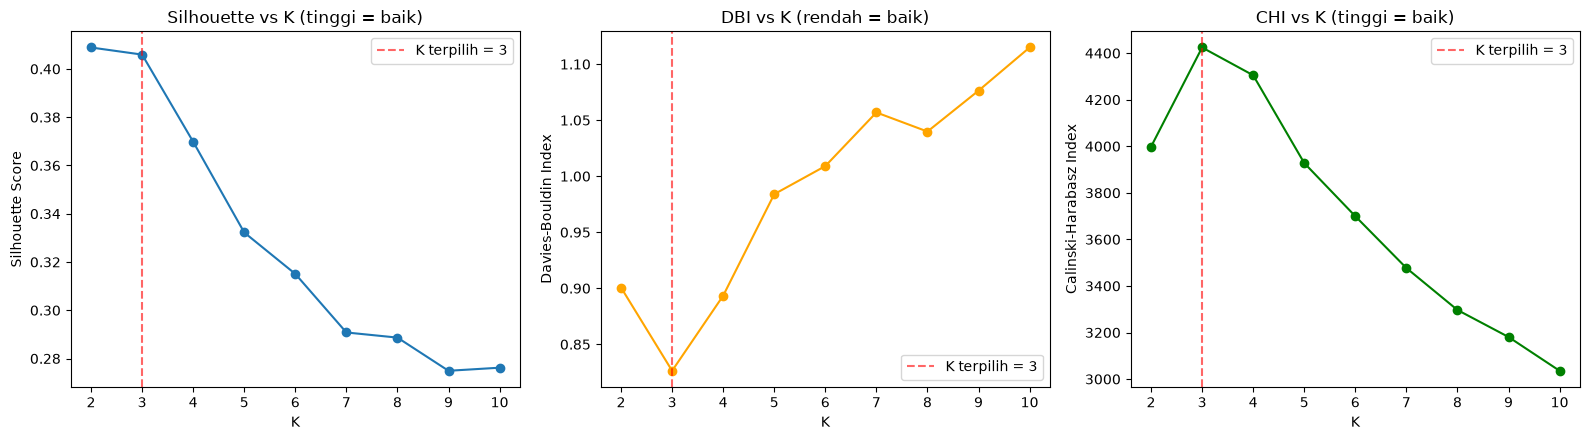

Garis merah putus-putus = K terpilih (K=3)


In [41]:
from src.visualization import plot_silhouette_by_k, plot_dbi_by_k, plot_chi_by_k, plot_clusters_pca

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_silhouette_by_k(metrics_df, selected_k, ax=axes[0])
plot_dbi_by_k(metrics_df, selected_k, ax=axes[1])
plot_chi_by_k(metrics_df, selected_k, ax=axes[2])
plt.tight_layout()
plt.savefig(CONFIG.output_dir / "evaluation_metrics_by_k.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Garis merah putus-putus = K terpilih (K={selected_k})")

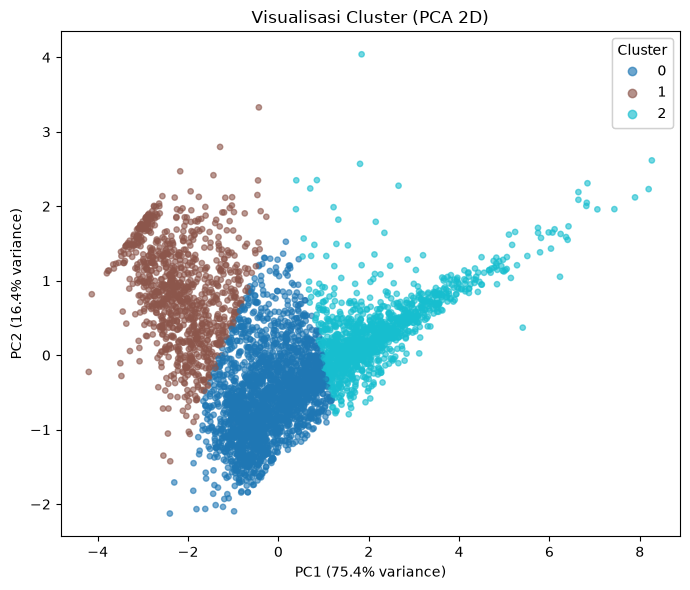

2 komponen PCA menjelaskan 91.8% variance total dari 4 fitur (PC1=75.4%, PC2=16.4%)


In [42]:
fig, ax = plt.subplots(figsize=(7, 6))
_, explained_var = plot_clusters_pca(X_scaled, final_model.labels_, random_state=CONFIG.random_state, ax=ax)
plt.tight_layout()
plt.savefig(CONFIG.output_dir / "clusters_pca.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"2 komponen PCA menjelaskan {explained_var.sum():.1%} variance total dari 4 fitur "
      f"(PC1={explained_var[0]:.1%}, PC2={explained_var[1]:.1%})")

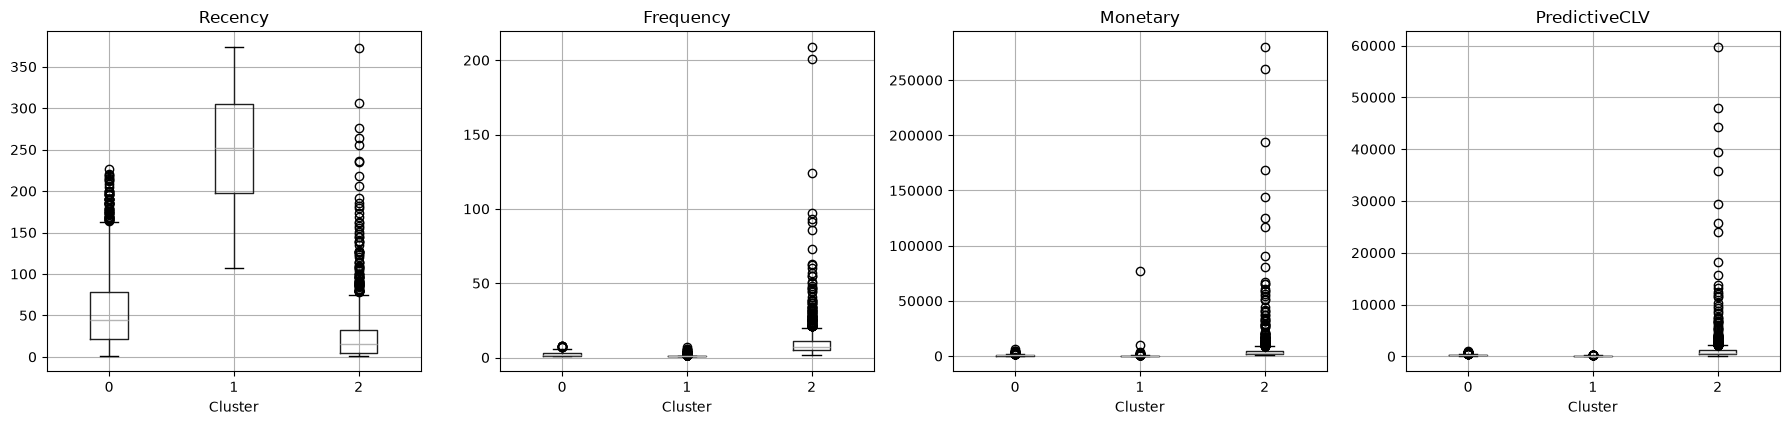

In [43]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, FEATURE_COLS):
    customer_segments.boxplot(column=col, by="Cluster", ax=ax)
    ax.set_title(col); ax.set_xlabel("Cluster")
plt.suptitle("")
plt.tight_layout()
plt.savefig(CONFIG.output_dir / "feature_distribution_by_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

In [44]:
print("="*70)
print("RINGKASAN AKHIR SEGMENTASI")
print("="*70)
print(f"Total customer           : {len(customer_segments):,}")
print(f"Fitur clustering         : {FEATURE_COLS}")
print(f"Kandidat K diuji          : {list(CONFIG.candidate_k)}")
print(f"K terpilih (multi-metric): {selected_k}")
print(f"Silhouette @ K terpilih  : {metrics_df.loc[metrics_df.K==selected_k,'Silhouette'].values[0]:.3f}")
print(f"DBI @ K terpilih         : {metrics_df.loc[metrics_df.K==selected_k,'DBI'].values[0]:.3f}")
print(f"CHI @ K terpilih         : {metrics_df.loc[metrics_df.K==selected_k,'CHI'].values[0]:.1f}")
print()
for _, r in final_profile.sort_values("ValueOrder").iterrows():
    print(f"  Cluster {int(r['Cluster'])} [{r['ProfileLabel']:20s}] "
          f"{int(r['NumCustomers']):>5,} customer ({r['PctCustomers']:>5.1f}%)")
print("="*70)
print("\nFile tersimpan di outputs/:")
for f in sorted(CONFIG.output_dir.glob("*")):
    print(f"  - {f.name}")

RINGKASAN AKHIR SEGMENTASI
Total customer           : 4,338
Fitur clustering         : ['Recency', 'Frequency', 'Monetary', 'PredictiveCLV']
Kandidat K diuji          : [2, 3, 4, 5, 6, 7, 8, 9, 10]
K terpilih (multi-metric): 3
Silhouette @ K terpilih  : 0.406
DBI @ K terpilih         : 0.826
CHI @ K terpilih         : 4424.3

  Cluster 2 [High Value / Loyal  ] 1,170 customer ( 27.0%)
  Cluster 0 [Potential           ] 2,184 customer ( 50.3%)
  Cluster 1 [At Risk             ]   984 customer ( 22.7%)

File tersimpan di outputs/:
  - cleaned_data.csv
  - cleaning_log.csv
  - cluster_profile.csv
  - clustering_evaluation.csv
  - clustering_evaluation_raw.csv
  - clusters_pca.png
  - clv_decile_table.csv
  - clv_evaluation_metrics.csv
  - clv_multi_split_evaluation.csv
  - clv_predictions.csv
  - customer_features.csv
  - customer_features_scaled.csv
  - customer_rfm.csv
  - customer_segments.csv
  - evaluation_metrics_by_k.png
  - feature_distribution_by_cluster.png
  - kmeans_final_model